# Lesson 5 · ARIMA, SARIMA & SARIMAX
**Phase 7: Time-Series Analysis & Forecasting** &nbsp;|&nbsp; **Week 14** &nbsp;|&nbsp; ⏱ ≈ 120 minutes

> 🎯 **By the end of this lesson you will be able to:**
    > - Explain **AR, MA, ARMA and ARIMA(p,d,q)** in plain language
> - Follow the **Box–Jenkins workflow**: identify → estimate → diagnose → forecast
> - Fit and interpret **SARIMA(p,d,q)(P,D,Q)ₘ** for seasonal data
> - Use **Fourier terms** for long seasonality (weekly data, m = 52)
> - Add exogenous drivers with **SARIMAX**: and respect what is known at forecast time
> - Evaluate the whole family with **walk-forward** validation

**Prerequisites:** Lessons 1 (ACF/PACF, stationarity) and 3 (walk-forward).

**How to work through this notebook:** read a section, *predict* what the next cell will show, run it, and compare.
Prediction before execution is the fastest way to build intuition. Problems come with progressive hints (open them one at a time:
struggling a little is where learning happens). Reference solutions live in `solutions/`.

In [1]:
import sys; sys.path.append("..")            # lets us import course_utils.py from the parent folder
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.tools.sm_exceptions         # (imported first: statsmodels registers its own warning filters on import)
import warnings; warnings.filterwarnings("ignore")   # keep the notebook readable; in real projects READ your warnings!
from course_utils import *                    # data loaders, metrics, plotting helpers, check()

## 1 · Decoding the acronym

**ARIMA(p, d, q)** = **A**uto**R**egressive **I**ntegrated **M**oving **A**verage. Three ideas glued together:

| Piece | Idea | Formula (for the stationary series $z_t$) | Plain English |
|---|---|---|---|
| **AR(p)** | regress on own past | $z_t = c + \phi_1 z_{t-1} + \dots + \phi_p z_{t-p} + \varepsilon_t$ | "today ≈ a fraction of yesterday + a shock" |
| **MA(q)** | regress on past *shocks* | $z_t = c + \varepsilon_t + \theta_1\varepsilon_{t-1} + \dots + \theta_q\varepsilon_{t-q}$ | "a shock keeps echoing for q periods, then dies" |
| **I(d)** | difference d times first | $z_t = \Delta^d y_t$ | "model the *changes*, not the levels" |

> 💡 **Analogy.** Ripples in a pond. **AR**: the water's current height depends on its recent heights (momentum). **MA**: a thrown pebble (shock) disturbs the pond for q seconds and then it's gone. **I**: if the whole pond is slowly draining, study the *change* in the water level, not the level.

Special cases to remember:
- ARIMA(0,1,0) = **random walk** = the **naive forecast**.
- ARIMA(0,1,1) = **simple exponential smoothing** (!). The two families overlap.
- ARIMA(0,2,2) ≈ Holt's linear trend.

### The Box–Jenkins workflow

```
  ┌────────────┐    ┌────────────┐    ┌──────────────┐    ┌────────────┐
  │ 1 IDENTIFY │ -> │ 2 ESTIMATE │ -> │ 3 DIAGNOSE   │ -> │ 4 FORECAST │
  │ plot, ADF, │    │ fit several│    │ residuals =  │    │ + intervals│
  │ ACF / PACF │    │ orders, AIC│    │ white noise? │    │ back-transf│
  └────────────┘    └────────────┘    └──────┬───────┘    └────────────┘
                                             └── not white? go back to 1
```

## 2 · Step 1: Identify (maize, log scale)

Why **log**? Maize price swings grow with the level (multiplicative); logs make variance roughly constant and turn price *changes* into % changes.

ADF p-value, log price      : 0.459  -> unit root (need d = 1)
ADF p-value, log difference : 0.0  -> stationary


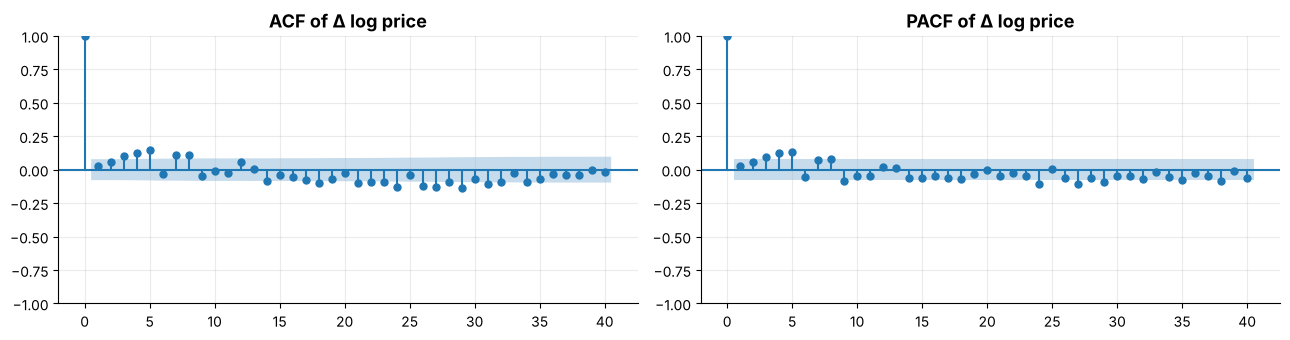

In [2]:
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

mz = load_weekly("maize")
y = np.log(mz["price"])

print("ADF p-value, log price      :", round(adfuller(y)[1], 3), " -> unit root (need d = 1)")
print("ADF p-value, log difference :", round(adfuller(y.diff().dropna())[1], 4), " -> stationary")

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
plot_acf(y.diff().dropna(), lags=40, ax=ax[0], title="ACF of Δ log price")
plot_pacf(y.diff().dropna(), lags=40, ax=ax[1], title="PACF of Δ log price", method="ywm"); plt.tight_layout(); plt.show()

The ACF/PACF of the differenced series are mostly inside the band with a few modest spikes, so any ARMA part will be *small*, and the leftover **seasonal** pattern shows up as slow ripples.
We let the data vote via **AIC** (Akaike Information Criterion: *fit minus a penalty for complexity*; lower is better).
We deliberately keep $p, q \le 1$ (**parsimony**): in a bigger grid the optimiser happily picks, e.g., ARIMA(2,1,2) whose AR and MA coefficients nearly *cancel each other* (±1.5 vs ∓1.5): a classic symptom of over-parameterisation that fits noise and often fails to converge.

## 3 · Step 2: Estimate: a small order search

In [3]:
aics = pd.DataFrame(index=[f"p={p}" for p in range(2)], columns=[f"q={q}" for q in range(2)], dtype=float)
for p in range(2):
    for q in range(2):
        aics.iloc[p, q] = ARIMA(y, order=(p, 1, q)).fit().aic
print("AIC of ARIMA(p,1,q) on log maize (lower = better):")
aics.round(1)

AIC of ARIMA(p,1,q) on log maize (lower = better):


,q=0,q=1
p=0,-2327.9,-2326.3
p=1,-2326.3,-2336.7


In [4]:
best_p, best_q = np.unravel_index(np.nanargmin(aics.values), aics.shape)
arima = ARIMA(y, order=(int(best_p), 1, int(best_q))).fit()
print(f"Chosen order: ARIMA({best_p},1,{best_q})")
print(arima.summary().tables[1])

Chosen order: ARIMA(1,1,1)
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.8608      0.088      9.747      0.000       0.688       1.034
ma.L1         -0.7870      0.108     -7.279      0.000      -0.999      -0.575
sigma2         0.0014   6.53e-05     21.113      0.000       0.001       0.002


> 🔎 **Reading the table:** `coef` is the estimate, `P>|z|` its p-value (small = the term matters), `sigma2` the shock variance. Coefficients near ±1 (or MA & AR terms that cancel each other) signal an over-parameterised model.

## 4 · Step 3: Diagnose: do the residuals look like white noise?
If the model captured all the structure, residuals should be **uncorrelated** with **mean 0** and roughly **normal**.

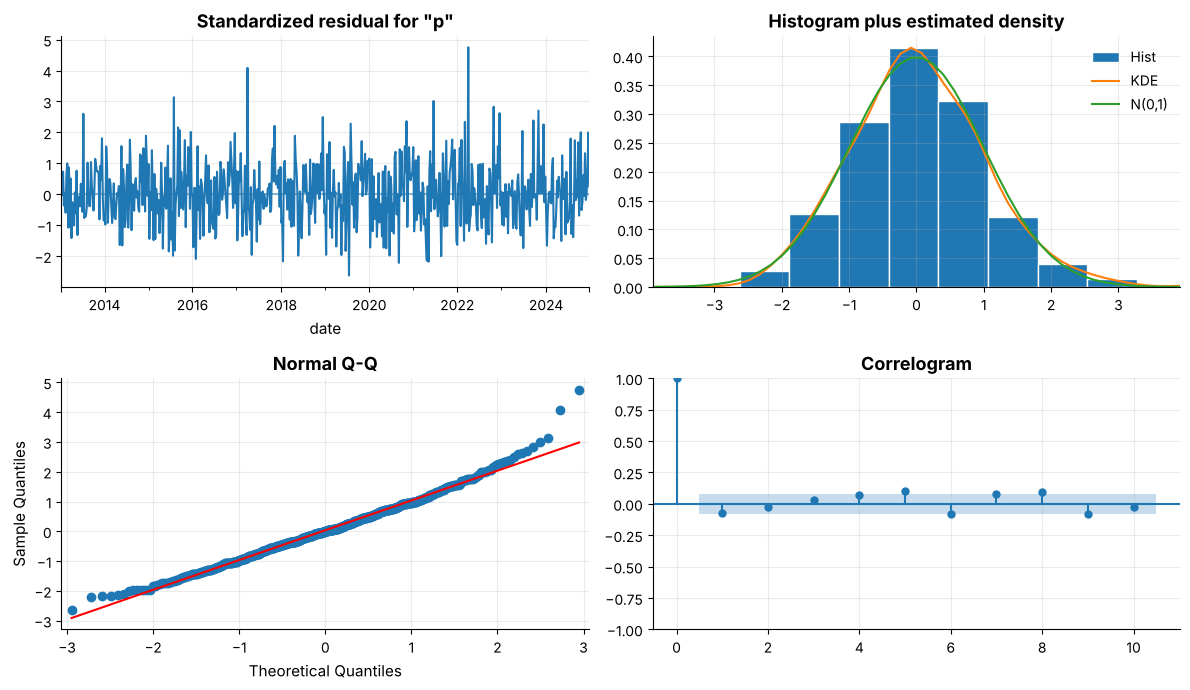

     lb_stat  lb_pvalue
10   31.7228     0.0004
26   59.8987     0.0002
52  124.7618     0.0000


In [5]:
arima.plot_diagnostics(figsize=(12, 7)); plt.tight_layout(); plt.show()

from statsmodels.stats.diagnostic import acorr_ljungbox
print(acorr_ljungbox(arima.resid[1:], lags=[10, 26, 52]).round(4))

**The four panels:** (1) residuals over time – no pattern, no volatility clusters; (2) histogram vs. normal; (3) Q–Q plot – points on the line; (4) correlogram – all bars inside the band.
**Ljung–Box** tests *"residuals are white noise"*: a small p-value (< 0.05) means structure is left. Here the seasonal wave is an obvious suspect → we'll add it in a moment.

## 5 · Step 4: Forecast with intervals (and back-transform!)
We modelled **log** prices, so forecasts must be exponentiated to get back to price units.

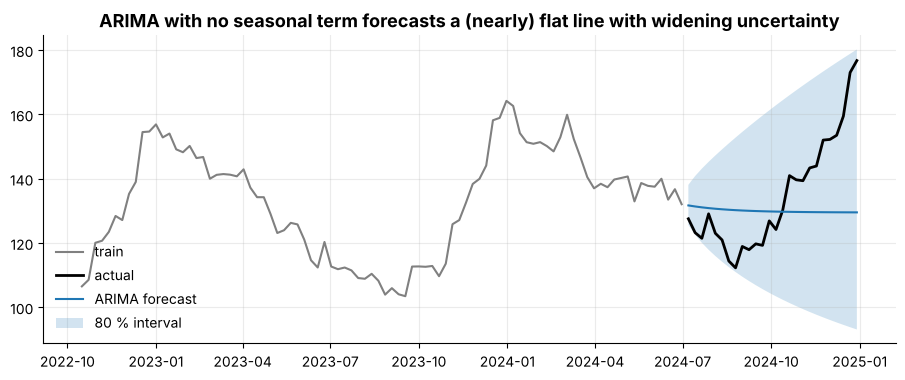

RMSE: 18.35 | naive: 17.6


In [6]:
h = 26
train_y, test_y = y.iloc[:-h], y.iloc[-h:]
m = ARIMA(train_y, order=(int(best_p), 1, int(best_q))).fit()
fc = m.get_forecast(h).summary_frame(alpha=0.2)          # 80 % interval, on the LOG scale

price_fc = np.exp(fc["mean"]); lo, hi = np.exp(fc["mean_ci_lower"]), np.exp(fc["mean_ci_upper"])
fig, ax = plt.subplots()
ax.plot(np.exp(train_y.iloc[-90:]), color="gray", label="train"); ax.plot(np.exp(test_y), color="black", lw=2, label="actual")
ax.plot(price_fc, color="tab:blue", label="ARIMA forecast"); ax.fill_between(price_fc.index, lo, hi, alpha=.2, label="80 % interval")
ax.legend(); ax.set_title("ARIMA with no seasonal term forecasts a (nearly) flat line with widening uncertainty"); plt.show()
print("RMSE:", round(rmse(np.exp(test_y), price_fc), 2), "| naive:", round(rmse(np.exp(test_y), fc_naive(np.exp(train_y), h)), 2))

> 💡 An ARIMA(p,1,q) with no seasonal terms and no drift basically *is* the naive forecast for a random-walk-like series; the 80 % band **fans out like a trumpet** as uncertainty accumulates.
> To do better we must add what the series genuinely has: **seasonality**.

## 6 · SARIMA: seasonal ARIMA

$$\text{SARIMA}(p,d,q)\,(P,D,Q)_m$$

- $(p,d,q)$: the usual non-seasonal part.
- $(P,D,Q)_m$: the *same* ideas applied at **seasonal lags** $m, 2m, \dots$: e.g. for monthly data $m = 12$: $D=1$ means $y_t - y_{t-12}$; $P$ and $Q$ are AR/MA terms at lags 12, 24, …

**Reading ACF/PACF for the seasonal part:** look at the lags that are multiples of $m$. A spike at lag 12 in the ACF (cutting off) suggests seasonal MA(1); a spike at lag 12 in the PACF suggests seasonal AR(1).

### Classic example: the airline model on log passengers

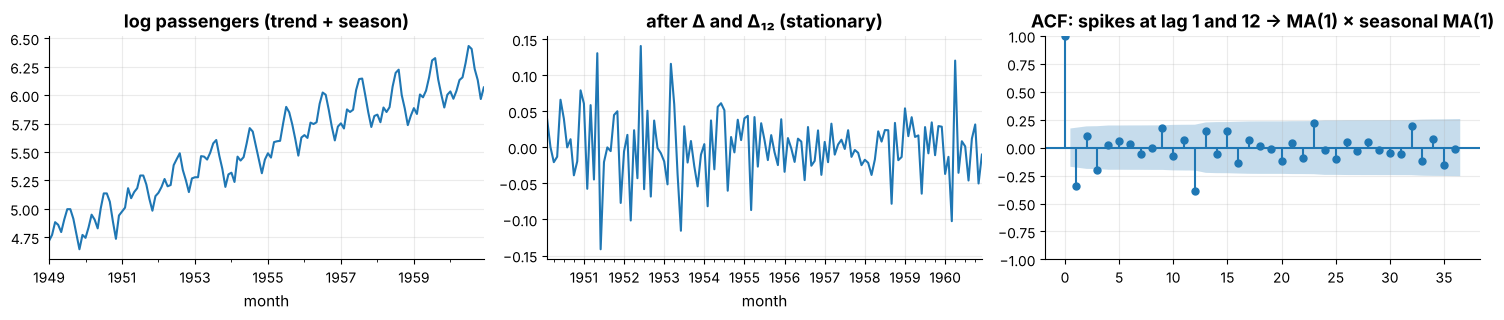

In [7]:
air = load_airline()
ly = np.log(air)
d = ly.diff().diff(12).dropna()                          # one regular + one seasonal difference
fig, ax = plt.subplots(1, 3, figsize=(15, 3.3))
ly.plot(ax=ax[0], title="log passengers (trend + season)"); d.plot(ax=ax[1], title="after ∆ and ∆₁₂ (stationary)")
plot_acf(d, lags=36, ax=ax[2], title="ACF: spikes at lag 1 and 12 → MA(1) × seasonal MA(1)"); plt.tight_layout(); plt.show()

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.3425      0.087     -3.923      0.000      -0.514      -0.171
ma.S.L12      -0.5407      0.105     -5.157      0.000      -0.746      -0.335
sigma2         0.0014      0.000      7.865      0.000       0.001       0.002


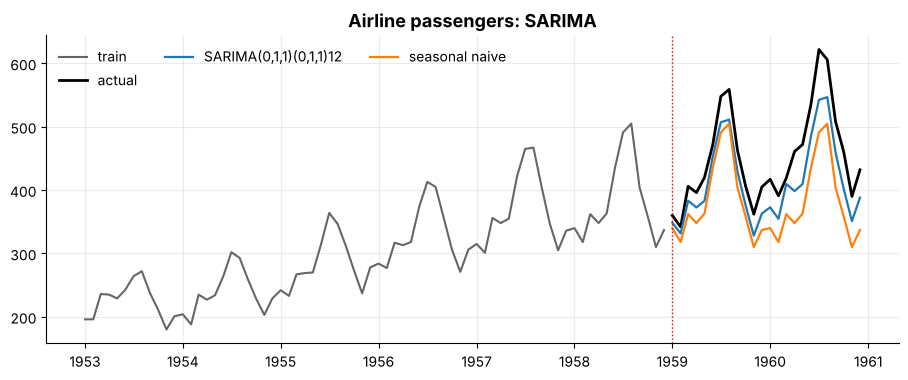

,MAE,RMSE,MAPE,sMAPE,MASE
"SARIMA(0,1,1)(0,1,1)12",39.437,43.173,8.514,8.949,1.380
seasonal naive,71.250,76.995,15.523,17.013,2.494


In [8]:
a_train, a_test = air.iloc[:-24], air.iloc[-24:]
sar = SARIMAX(np.log(a_train), order=(0, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)
print(sar.summary().tables[1])
fc_sar = np.exp(sar.get_forecast(24).predicted_mean)
fcs = {"SARIMA(0,1,1)(0,1,1)12": fc_sar.values, "seasonal naive": fc_snaive(a_train, 24, m=12)}
plot_forecasts(a_train, a_test, fcs, "Airline passengers: SARIMA", last_train=72); plt.show()
score_table(a_test, fcs, y_train=a_train, m=12)

## 7 · The problem with *weekly* seasonality (m = 52)

A SARIMA with m = 52 must track 52 seasonal lags in its state space → huge, slow, and often numerically unstable (and `statsmodels` will happily try for minutes).
**Professional workaround: dynamic harmonic regression:** model the seasonal shape with a few **Fourier terms** as exogenous regressors and let ARIMA handle the *errors*:

$$y_t = \underbrace{\sum_{k=1}^{K}\big[a_k\sin(2\pi k t/365.25) + b_k\cos(2\pi k t/365.25)\big]}_{\text{smooth annual shape}} + \eta_t,\qquad \eta_t \sim \text{ARIMA}(p,d,q)$$

Only $2K$ parameters instead of 52! And Fourier terms are **deterministic**, so we know them for any future date: no leakage worry.

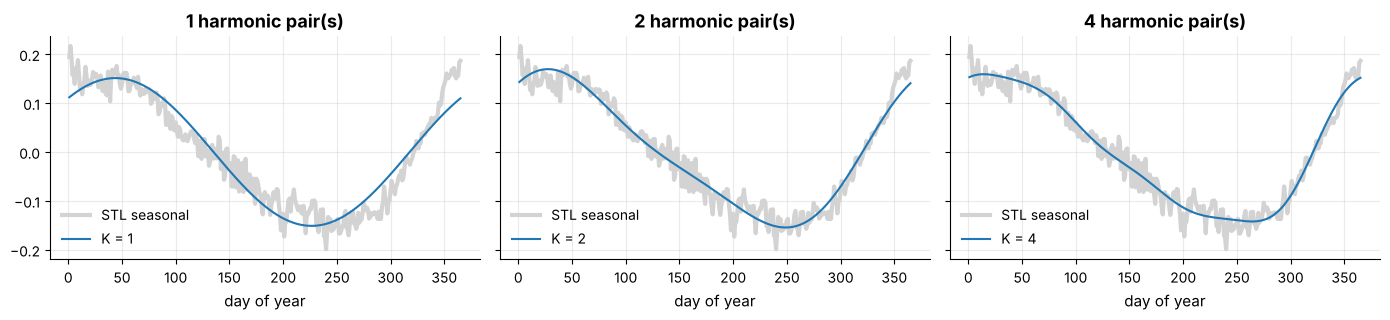

In [9]:
from statsmodels.tsa.seasonal import STL
seas = STL(y, period=52, robust=True).fit().seasonal                      # the "true" yearly shape (log scale)
seas_by_doy = seas.groupby(seas.index.dayofyear).mean()
days = pd.date_range("2023-01-01", periods=365)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.3), sharey=True)
for ax, K in zip(axes, (1, 2, 4)):
    A = np.c_[np.ones(len(seas)), fourier_terms(seas.index, K).values]        # least squares: seasonal ≈ c + Σ harmonics
    beta, *_ = np.linalg.lstsq(A, seas.values, rcond=None)
    shape = np.c_[np.ones(365), fourier_terms(days, K).values] @ beta
    ax.plot(seas_by_doy.index, seas_by_doy.values, color="lightgray", lw=3, label="STL seasonal")
    ax.plot(np.arange(1, 366), shape, label=f"K = {K}")
    ax.set_title(f"{K} harmonic pair(s)"); ax.legend(); ax.set_xlabel("day of year")
plt.tight_layout(); plt.show()

K = 1 gives a single smooth hill; K = 2–4 captures the sharper shape. Choose **K** by AIC/BIC or by walk-forward error (Problem 5.4).

## 8 · SARIMAX: adding exogenous drivers

The **X** stands for *eXogenous*: outside variables that help explain the series: for us, **rainfall, fuel prices, festivals**.
In `statsmodels`, `SARIMAX(y, exog=X, ...)` fits  $y_t = \beta' x_t + \eta_t$ with SARIMA errors $\eta_t$.

> ⚠️ **The exogenous-variable trap.** To forecast 8 weeks ahead you need the **future values of X**. There are exactly three legitimate sources:
> 1. **Deterministic** variables known in advance: Fourier terms, holidays, festival flags.
> 2. **Lagged** variables: rainfall *8 weeks ago* is known today for any horizon h ≤ 8.
> 3. **Separately forecasted** variables (e.g. a weather forecast): these carry *their own* forecast error.
>
> Using this week's actual rainfall to "forecast" this week's price is **not** a forecast: it's a nowcast with leakage. (In our data, `arrivals_tonnes` is exactly such a trap: it is observed together with the price.)

Our simulated market was built so rainfall affects prices ~8 weeks later and fuel costs pass through with a delay: realistic supply-chain lags. Let's use them:

In [10]:
def build_exog(df, K=3):
    """Exogenous table for weekly market data: Fourier seasonality + lagged drivers + festival flag.
       Every driver is lagged >= 8 weeks, so it is known for any forecast horizon up to h = 8."""
    X = fourier_terms(df.index, K)
    X["rain6_l8"] = (df["rainfall_mm"].rolling(6).mean().shift(8) / 30)      # 6-week average rain, 8 weeks ago (scaled)
    X["fuel_l8"] = np.log(df["fuel_index"] / 100).shift(8)                      # log fuel index, 8 weeks ago
    X["fest"] = df["festival_flag"]                                             # calendar-known
    return X

X = build_exog(mz)
valid = X.dropna().index                                  # the first 13 weeks lack lagged drivers
cols_f = [c for c in X.columns if c[:3] in ("sin", "cos")]
cols_all = cols_f + ["rain6_l8", "fuel_l8", "fest"]

fit_f = SARIMAX(y.loc[valid], exog=X.loc[valid, cols_f], order=(1, 1, 1), trend="n").fit(disp=False)
fit_a = SARIMAX(y.loc[valid], exog=X.loc[valid, cols_all], order=(1, 1, 1), trend="n").fit(disp=False)
print(f"AIC  Fourier only: {fit_f.aic:9.1f}    Fourier + drivers: {fit_a.aic:9.1f}   (lower = better)")
print("\nEstimated effects on LOG price:")
print(fit_a.params[["rain6_l8", "fuel_l8", "fest"]].round(3))

AIC  Fourier only:   -2380.6    Fourier + drivers:   -2737.5   (lower = better)

Estimated effects on LOG price:
rain6_l8   -0.130
fuel_l8     0.164
fest        0.045
dtype: float64


**Interpretation (this is the fun part):**
- `rain6_l8 < 0`: more rain 8 weeks ago ⇒ lower prices now (good harvest ⇒ more supply). Drought ⇒ price spike. ✅ Makes agronomic sense.
- `fuel_l8 > 0`: dearer transport fuel ⇒ dearer food (costs pass through).
- `fest ≈ 0.045`: festival weeks add about **4.5 %** to price. *We built the simulation with a 4 % bump*: the model recovered it. 🎯

### 🏁 The ARIMA-family tournament (walk-forward, h = 8)
We refit at every 8th origin. Note how `make_sarimax` only ever uses exog rows available **at or before the origin** (history) plus *known-in-advance* rows for the future.

In [11]:
def make_sarimax(cols, X=X, valid=valid, order=(1, 1, 1)):
    def f(train, h):
        idx = train.index.intersection(valid)                              # history rows with complete exog
        tr = np.log(train.loc[idx])
        fut = pd.date_range(train.index[-1], periods=h + 1, freq="W-SUN")[1:]
        mod = SARIMAX(tr, exog=X.loc[idx, cols] if cols else None, order=order, trend="n").fit(disp=False)
        return np.exp(mod.forecast(h, exog=X.loc[fut, cols] if cols else None).values)
    return f

contenders = {"naive": fc_naive,
              "ARIMA(1,1,1)": make_sarimax([]),
              "ARIMAX + Fourier": make_sarimax(cols_f),
              "ARIMAX + Fourier + drivers": make_sarimax(cols_all)}
H = 8
wfs = {n: walk_forward(mz["price"], f, initial=470, horizon=H, step=8) for n, f in contenders.items()}
tab = pd.DataFrame({n: {"MAE": mae(w.actual, w.forecast), "RMSE": rmse(w.actual, w.forecast)} for n, w in wfs.items()}).T
tab["skill vs naive"] = 1 - tab["RMSE"] / tab.loc["naive", "RMSE"]
print(f"{wfs['naive'].origin.nunique()} forecast origins, horizon 1..{H}")
tab.round(3)

19 forecast origins, horizon 1..8


,MAE,RMSE,skill vs naive
naive,9.724,12.081,0.000
"ARIMA(1,1,1)",9.673,12.006,0.006
ARIMAX + Fourier,6.783,9.233,0.236
ARIMAX + Fourier + drivers,5.536,7.419,0.386


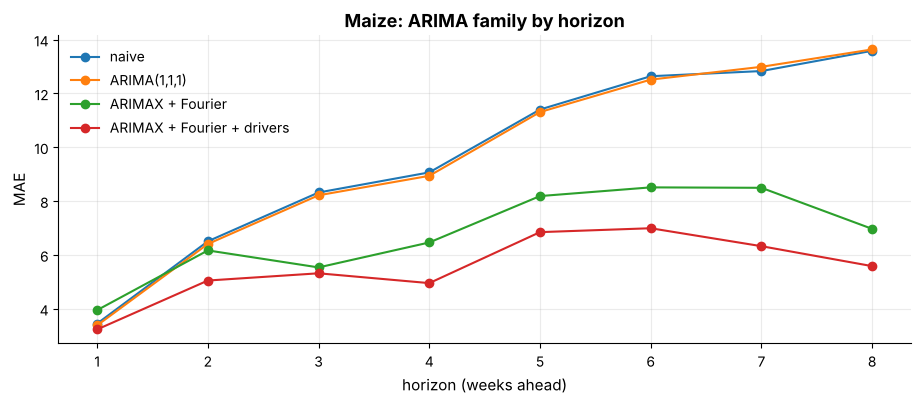

In [12]:
fig, ax = plt.subplots()
for n, w in wfs.items():
    bh = scores_by_horizon(w); ax.plot(bh.index, bh["MAE"], marker="o", label=n)
ax.set_xlabel("horizon (weeks ahead)"); ax.set_ylabel("MAE"); ax.legend(); ax.set_title("Maize: ARIMA family by horizon"); plt.show()

### 🧠 What the tournament teaches
1. **Plain ARIMA ≈ naive.** For a random-walk-like price, differencing already captures nearly everything the ARMA part can.
2. **Seasonality (Fourier terms) gives a large jump**: the annual harvest cycle is predictable information.
3. **Outside drivers add a second jump**: and, crucially, they help *more at longer horizons*, where the series' own recent history says little.
4. We got these gains while *respecting time*: no future rainfall, no shuffling.

### ⚠️ Pitfalls checklist
| Pitfall | Why it hurts | Cure |
|---|---|---|
| Forgetting to back-transform logs | forecasts of 4.5 instead of 90 | `np.exp(...)` |
| Comparing AIC across different `d` or log vs raw | AIC is only comparable for the *same* data | compare out-of-sample error instead |
| Convergence warnings / nonsense fit | optimiser failed (we hit this with a drift term plus regressors!) | simplify (`trend='n'`), rescale exog, try different start |
| Exog not known at forecast time | silent leakage | use lags ≥ horizon, deterministic features, or forecast the exog |
| Fitting m = 52 SARIMA | slow and unstable | Fourier terms (or aggregate to monthly) |
| Over-differencing | negative MA(1) ≈ −1 | difference only as needed |
| Trusting intervals blindly | models assume the structure is right | check coverage in walk-forward |

## 🧩 Practice problems

### 🧩 Problem 5.1 · Identify and fit: tomato  ·  🟢 Easy

Tomato prices are stationary in levels (Lesson 1). On the **log tomato price**, fit `ARIMA(order=(p,0,q))` for the candidates
  `(1,0,0)`, `(2,0,0)`, `(1,0,1)`, `(2,0,1)`, then choose the one with the lowest **AIC**. Store the winning order in `best_order` and print its AR coefficient(s).

<details><summary>💡 Hint 1</summary>

`from statsmodels.tsa.arima.model import ARIMA`; `res = ARIMA(y, order=(1, 0, 0)).fit()`; the AIC is `res.aic`.

</details>

<details><summary>💡 Hint 2</summary>

Loop over the candidate orders and keep a dict `{order: aic}`; `min(d, key=d.get)` returns the best key.

</details>

<details><summary>💡 Hint 3</summary>

Coefficients: `res.params`: look for names starting with `ar.L`.

</details>

In [13]:
from statsmodels.tsa.arima.model import ARIMA
lt = np.log(load_weekly('tomato')['price'])
best_order = None
# YOUR CODE HERE
print(best_order)

None


### 🧩 Problem 5.2 · Residual diagnostics with Ljung–Box  ·  🟡 Medium

For the best tomato model from 5.1, run the **Ljung–Box test** (`statsmodels.stats.diagnostic.acorr_ljungbox`) on the residuals at lags 10 and 26.
  The null hypothesis is *'residuals are white noise'*. Is it rejected? What would a rejection mean for your model?

<details><summary>💡 Hint 1</summary>

`acorr_ljungbox(res.resid, lags=[10, 26])` returns a DataFrame with `lb_stat` and `lb_pvalue`.

</details>

<details><summary>💡 Hint 2</summary>

A p-value below 0.05 ⇒ the residuals still contain autocorrelation.

</details>

<details><summary>💡 Hint 3</summary>

If it is rejected, which part of the model might be missing? (think: tomato has strong seasonality!)

</details>

In [14]:
from statsmodels.stats.diagnostic import acorr_ljungbox
# YOUR CODE HERE

### 🧩 Problem 5.3 · Grid-search a SARIMA on the airline data  ·  🟡 Medium

On **log airline passengers** (hold out the last 24 months) fit `SARIMAX(order=(p,1,q), seasonal_order=(P,1,Q,12))` for every combination of
  `p, q, P, Q ∈ {0, 1}`. Pick the best by AIC. Forecast the 24 held-out months (remember to `np.exp` back!) and report RMSE next to the Holt-Winters
  multiplicative RMSE from Lesson 4 (≈ 41).

<details><summary>💡 Hint 1</summary>

`itertools.product([0, 1], repeat=4)` gives all 16 combinations.

</details>

<details><summary>💡 Hint 2</summary>

`SARIMAX(np.log(train), order=(p, 1, q), seasonal_order=(P, 1, Q, 12)).fit(disp=False)`; AIC is `res.aic`.

</details>

<details><summary>💡 Hint 3</summary>

`np.exp(res.forecast(24))` brings forecasts back to passenger counts.

</details>

In [15]:
import itertools
from statsmodels.tsa.statespace.sarimax import SARIMAX
air = load_airline()
train, test = air.iloc[:-24], air.iloc[-24:]
# YOUR CODE HERE

### 🧩 Problem 5.4 · How many Fourier pairs?  ·  🟡 Medium

For weekly **onion** log prices, fit `SARIMAX(order=(1,1,1), trend='n')` with Fourier terms `K = 1 … 6` as exogenous regressors (`fourier_terms(index, K)`)
  and choose `K` by **AIC** (and by **BIC**, which penalises complexity harder). Do they agree?

<details><summary>💡 Hint 1</summary>

`X = fourier_terms(y.index, K)` has `2K` columns.

</details>

<details><summary>💡 Hint 2</summary>

`SARIMAX(y, exog=X, order=(1, 1, 1), trend='n').fit(disp=False)`; read `res.aic` and `res.bic`.

</details>

<details><summary>💡 Hint 3</summary>

More harmonics = a more flexible seasonal shape, but more parameters and risk of over-fitting.

</details>

In [16]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
y = np.log(load_weekly('onion')['price'])
# YOUR CODE HERE

### 🧩 Problem 5.5 · Do rainfall and fuel help for tomato?  ·  🔴 Challenge

Repeat the worked-example experiment for **tomato**: walk-forward at horizon 8 (`initial=470`, `step=8`) comparing
  (a) naive, (b) ARIMA(1,1,1) + Fourier (K=3), and (c) ARIMA(1,1,1) + Fourier + `rain6_l8` + `fuel_l8` + `fest`.
  Use the `build_exog` helper from the worked example. Does adding the exogenous drivers help? Why might the answer differ from maize?

<details><summary>💡 Hint 1</summary>

Reuse the pattern `make_sarimax(cols)` from the worked example, but build the exog table from the **tomato** DataFrame.

</details>

<details><summary>💡 Hint 2</summary>

Remember: only use exogenous values that will be *known* at forecast time (here: rain and fuel lagged 8 weeks, valid for h ≤ 8).

</details>

<details><summary>💡 Hint 3</summary>

Compare MAE and RMSE with `mae`/`rmse`. Tomato's price noise is much larger (see `generate_data.py`: noise 0.075 vs 0.020 for maize).

</details>

In [17]:
tomato = load_weekly('tomato')
# YOUR CODE HERE (build_exog and make_sarimax from the worked example are available)

## ✅ Recap
- **ARIMA(p,d,q)**: AR (momentum) + I (differencing) + MA (shock echoes). ARIMA(0,1,0) = naive.
- **Box–Jenkins**: identify (ACF/PACF, ADF) → estimate (AIC) → diagnose (residual ACF, Ljung–Box) → forecast (+ intervals, back-transform).
- **SARIMA** adds seasonal AR/MA/differencing at lag *m*; for long periods use **Fourier terms**.
- **SARIMAX** brings outside drivers: but **only if they're known when you forecast**.
- Judge with **walk-forward**, never with in-sample AIC alone.

### 🔮 Next lesson
Statistical models rest on assumptions about linearity and error structure. **Lesson 6** reframes forecasting as *supervised learning*: engineer lag features and unleash Linear Regression, Random Forest, Gradient Boosting and XGBoost, and discover why tree models can't extrapolate a trend!